# 4. Accuracy and the energy-accuracy trade-off (RQ2)

To restate: accuracy is analysed per question, not per run. Every repetition gives identical
answers (notebook 1), so the 100 questions are the sample, and each question has one paired
outcome per strategy.

- Cochran's Q test across the three strategies, then exact McNemar tests per pair.
- The RQ2 trade-off quantities are descriptive, with 95% bootstrap confidence intervals:
  energy saving SE, accuracy change ΔA, η and F_l.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

import experiment_data as data
import stats
import style

style.apply()
pd.set_option("display.precision", 3)
runs = data.load_runs()

import numpy as np
answers = data.load_answers()

## 4.1 Accuracy and paired outcomes

In [2]:
print("correct answers:", answers.sum().to_dict())

for first, second in [("R", "L"), ("R", "S"), ("S", "L")]:
    table = pd.crosstab(answers[first].map({1: f"{first} correct", 0: f"{first} wrong"}),
                        answers[second].map({1: f"{second} correct", 0: f"{second} wrong"}))
    display(table)

correct answers: {'S': 50, 'L': 88, 'R': 73}


L,L correct,L wrong
R,,
R correct,73,0
R wrong,15,12


S,S correct,S wrong
R,,
R correct,48,25
R wrong,2,25


L,L correct,L wrong
S,,
S correct,48,2
S wrong,40,10


In [3]:
from statsmodels.stats.contingency_tables import cochrans_q, mcnemar

q = cochrans_q(answers[data.STRATEGIES].to_numpy())
print(f"Cochran's Q = {q.statistic:.1f}, p = {q.pvalue:.2g}")

rows = []

for first, second in [("R", "L"), ("R", "S"), ("S", "L")]:
    table = pd.crosstab(answers[first], answers[second]).reindex(index=[0, 1], columns=[0, 1], fill_value=0)
    only_first, only_second = table.at[1, 0], table.at[0, 1]
    rows.append({"comparison": f"{first} - {second}",
                 "accuracy difference (pp)": answers[first].mean() * 100 - answers[second].mean() * 100,
                 f"only first correct": only_first, f"only second correct": only_second,
                 "exact McNemar p": mcnemar(table.to_numpy(), exact=True).pvalue})
    
pd.DataFrame(rows).set_index("comparison")

Cochran's Q = 52.3, p = 4.3e-12


,accuracy difference (pp),only first correct,only second correct,exact McNemar p
comparison,,,,
R - L,-15.0,0,15,6.104e-05
R - S,23.0,25,2,5.648e-06
S - L,-38.0,2,40,4.111e-10


**Confidence intervals for the accuracy differences.** Resample the 100 questions with replacement 10,000 times, keeping each question's
three outcomes together.

In [4]:
rng = np.random.default_rng(42)
indices = rng.integers(0, len(answers), size=(10_000, len(answers)))
outcomes = answers[data.STRATEGIES].to_numpy()
boot = {s: outcomes[:, i][indices].mean(axis=1) * 100 for i, s in enumerate(data.STRATEGIES)}

def ci(values):
    return np.percentile(values, [2.5, 97.5]).round(1)

for first, second in [("R", "L"), ("R", "S")]:
    point = 100 * (answers[first].mean() - answers[second].mean())
    print(f"ΔA {first} - {second} = {point:+.0f} pp, 95% CI {ci(boot[first] - boot[second])}")

ΔA R - L = -15 pp, 95% CI [-22.  -8.]
ΔA R - S = +23 pp, 95% CI [14. 32.]


## 4.2 Energy saving, efficiency and routing share

**Energy saving** SE = 100 × (1 − mean E_R / mean E_L).

In [5]:
energy = {s: runs.loc[runs["strategy"] == s, "energy_j"].to_numpy() for s in data.STRATEGIES}
saving = 100 * (1 - energy["R"].mean() / energy["L"].mean())
boot_saving = [100 * (1 - rng.choice(energy["R"], 30).mean() / rng.choice(energy["L"], 30).mean())
               for _ in range(10_000)]
print(f"SE = {saving:.2f}%, 95% CI {ci(boot_saving)}")
print(f"absolute saving: {energy['L'].mean() - energy['R'].mean():.0f} J per run, "
      f"{(energy['L'].mean() - energy['R'].mean()) / 100:.1f} J per question")
print(f"F_l (questions routed to the large model): {runs.loc[runs['strategy'] == 'R', 'n_to_large'].iloc[0]}%")

runs.groupby("strategy", observed=True)[["accuracy_pct", "energy_per_query_j", "efficiency_correct_per_kj"]].mean()

SE = 3.13%, 95% CI [3.  3.3]
absolute saving: 897 J per run, 9.0 J per question
F_l (questions routed to the large model): 66%


,accuracy_pct,energy_per_query_j,efficiency_correct_per_kj
strategy,,,
S,50.0,148.034,3.378
L,88.0,286.938,3.067
R,73.0,277.966,2.626


The run-to-run difference in energy is smaller than the markers in the plot below.

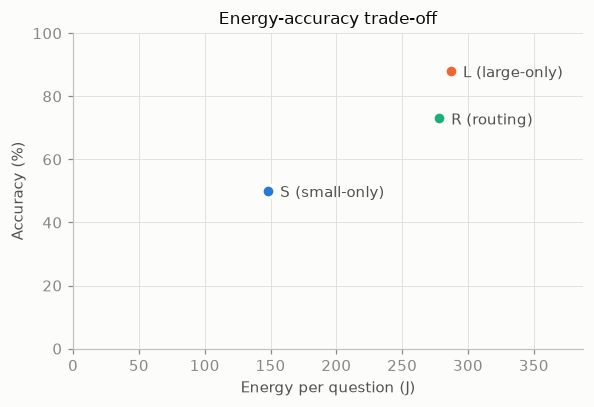

In [7]:
summary = runs.groupby("strategy", observed=True).agg(
    accuracy=("accuracy_pct", "mean"), energy=("energy_per_query_j", "mean"))
fig, ax = plt.subplots(figsize=(5.5, 3.8))

for strategy, row in summary.iterrows():
    ax.scatter(row["energy"], row["accuracy"], s=70, color=style.COLORS[strategy], zorder=3,
               edgecolor="#fcfcfb", linewidth=2)
    ax.annotate(style.label(strategy), (row["energy"], row["accuracy"]), xytext=(8, -4),
                textcoords="offset points", color=style.SECONDARY)
    
ax.set_xlabel("Energy per question (J)")
ax.set_ylabel("Accuracy (%)")
ax.set_xlim(0, summary["energy"].max() * 1.35)
ax.set_ylim(0, 100)
ax.set_title("Energy-accuracy trade-off")

plt.tight_layout()

## 4.3 Why does routing save so little energy?

This section is for interpretation. It looks at:

- **The routing decisions on the 100 experiment questions**, compared to what each model
  actually answered under S and L.
- **What R would cost if it just combined the two models' costs**, compared with what
  R actually used.

In [9]:
from sklearn.metrics import roc_auc_score

routed = data.load_queries("run_2_repetition_0").set_index("qid")
decisions = pd.DataFrame({"routed_to": routed["model"], "small_correct": answers["S"],
                          "large_correct": answers["L"]})

display(pd.crosstab(decisions["routed_to"], [decisions["small_correct"], decisions["large_correct"]],
                    rownames=["routed to"], colnames=["S correct", "L correct"]))

print(f"router AUC on the experiment questions: {roc_auc_score(answers['S'], routed['p_small_correct']):.2f}"
      " (0.5 = chance)")

per_question = runs.groupby("strategy", observed=True)["energy_per_query_j"].mean()
share_large = (routed["model"] == "large").mean()
mix = share_large * per_question["L"] + (1 - share_large) * per_question["S"]

print(f"weighted mix of S and L costs: {mix:.0f} J/question; measured R: {per_question['R']:.0f} J/question")

S correct  0      1    
L correct  0   1  0   1
routed to              
large      8  25  2  31
small      2  15  0  17

router AUC on the experiment questions: 0.45 (0.5 = chance)
weighted mix of S and L costs: 240 J/question; measured R: 278 J/question


**Notes**

- **Accuracy.** L is right on 88 questions, R on 73, S on 50.
  - All three strategies differ (Cochran's Q p ≈ 4·10⁻¹²), and so does every pair (exact
    McNemar p < 10⁻⁴).
  - R − L = −15 pp, 95% CI [−22, −8]. This is the **accuracy cost** of routing.
  - R is never right where L is wrong: its correct answers are a subset of L's.
  - The report deliberately makes no non-inferiority claim (Section 4.5).
- **Routing barely saves energy. The reasin is (probably) not the router:**
  - R sends 66% of questions to the large model, so most of the work is the same as under L.
  - Under R, both models are loaded and both GPUs are active, while the per-run baseline
    (the CPU's ~98 W) is paid for the whole run time.
  - The "weighted mix" line estimates R's cost if each question simply cost what it costs
    under S or L: 240 J. Measured R is 278 J, about 38 J per question more.
  - A likely part of that extra: under R both GPUs hold a model all the time. The 2B
    model's GPU averages 48 W under R at only 18% utilization, versus 12–15 W for an
    empty GPU (notebook 1). That's an interpretation to check, not a finding.
- **On these 100 questions, the router does no better than chance.** Its AUC is 0.45;
  0.5 means it can't tell easy questions from hard ones.
  - Of the 34 questions it sends to the small model, the small model gets 17 right: 50%,
    exactly its overall rate.
  - 15 of those 34 are questions L would have answered correctly. That is precisely the
    15 pp accuracy loss.
  - Worth comparing with the router's holdout accuracy from training: a router that worked
    on the train split but not here would point to overfitting, or to question text
    simply saying little about difficulty.